# CS1 - Full Formation Evaluation of a North Sea Discovery Well (30/6-5)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/case_studies/cs1_full_formation_evaluation_30_6-5.ipynb)

**Petrophys Case Studies - Project 1**

This is not a single-module tutorial. It is an end-to-end *interpretation project*
with a concrete deliverable: a formation evaluation of a discovery well and a
formation-by-formation recommendation of **where to perforate**.

**What you will learn**

- How to run one auditable interpretation with `pp.interpret` and read its step trace.
- How to check *where* the net-pay flag fired before trusting any total.
- How to roll the result up by formation with `result.formation_summary(..., rank="formation")`
  and turn it into a ranked completion plan.
- Why a whole-well net-pay total can mislead, and how choosing the reservoir interval fixes it.

**Prerequisites.** Lessons 00-01 (loading data), 07 (water saturation), 09 (net pay - it also
reconciles this well's Rw) and 10-11 (workflow traces and formation summaries). The base
install is enough; no optional extras are needed.

We follow the standard case-study spine:

1. **The brief** - the business question and why it matters.
2. **The well and data** - what we have, what is missing.
3. **Workflow plan** - the chain of interpretation steps and why in this order.
4. **Execution** - one `pp.interpret` run, with its step trace used as an audit, and a check
   of where the pay flag fired.
5. **Integrated result** - a per-formation results table and a multi-track interpretation plot.
6. **Interpretation and deliverable** - what the numbers mean, and the ranked completion picks.
7. **Limitations and assumptions** - honest caveats.
8. **Appendix** - how to re-run on another well and hand off the results.

> This lesson *uses* the library end-to-end and references the Part A / Part B tutorials for
> the underlying physics (Vcl from GR, density-neutron porosity, Archie saturation, net-pay
> cutoffs). It does not re-teach those basics.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Part 1 - The brief

> **From:** Subsurface team lead, North Sea development asset.
> **Subject:** Well 30/6-5 - full formation evaluation and completion recommendation.
>
> We have just finished logging discovery well **30/6-5** (Oseberg Øst, Norwegian North Sea).
> Wireline is in. Before we design the completion, I need a **defensible, auditable formation
> evaluation** of the whole logged section and a **ranked list of intervals to perforate**.
> Tell me which zones are pay, how good they are (porosity, water saturation, permeability),
> and where you would put the guns first. Flag anything you had to assume.

**Why it matters.** The completion decision commits real money. Perforate the wrong zone and you
produce water or nothing; miss a good zone and you leave reserves behind. The recommendation has
to be traceable - every cutoff and every assumed parameter must be visible so the reservoir
engineer can challenge it. That auditability is exactly what the *dynamic workflow* trace gives us.

**The deliverable (three artifacts):**

- **(a)** a multi-track interpretation / log plot summarizing the evaluation;
- **(b)** a per-formation results table (net pay, average PHIE, average Sw, hydrocarbon pore
  thickness index);
- **(c)** a ranked list of candidate completion intervals with written rationale.

## Part 2 - The well and the data

**Well 30/6-5** is a GeoLink clastic well from Oseberg Øst, logged in **metres**. It penetrates
the Norwegian North Sea section from the shallow Nordland and Hordaland groups, through the
Cretaceous and the Viking Group mudstones (Draupne and Heather formations), into the Middle Jurassic
**Brent Group** sands - `BRENT GP.` in the bundled tops, with the **Ness** and **Etive**
formations inside it - and on through the Dunlin Group to the **Statfjord Group** near total depth
(the bundled tops keep the picks' label `Statfjord Fm.`).

What we have and what we are missing drives every modelling choice below, so we inventory it first.

In [2]:
import warnings

import pandas as pd
import petrophys as pp

pd.set_option("display.precision", 3)
well = pp.read(pp.sample("30_6-5"))
TOPS = pp.sample("formations_30_6-5")
pd.DataFrame(well.describe()["curves"])

,mnemonic,unit,description,valid_fraction
0,LITHOLOGY_GEOLINK,_,Lithology_geolink,0.484
1,CALI,in,CALI,0.996
2,DRHO,g/cm3,DRHO,0.786
3,NPHI,m3/m3,NPHI,0.786
4,RHOB,g/cm3,RHOB,1.000
5,PEF,b/e,PEF,0.116
6,GR,gAPI,GR,1.000
7,DTC,us/ft,DTC,0.996
8,DTE,us/ft,DTE,0.996
9,RDEP,ohm.m,RDEP,1.000


The table is the inventory: every curve with its unit and the share of the logged interval it
covers. Grouped into the log families the interpretation needs:

- **Gamma ray / clay:** `GR`, `SP`. **Porosity:** `RHOB`, `NPHI`, `DTC`. **Resistivity:**
  `RDEP`, `RMED`, `RSHA`. **Borehole:** `CALI`, `BS`, `DRHO`.
- **Lithology aids:** `PEF` and the vendor lithology log `LITHOLOGY_GEOLINK`. PEF covers only
  12% of the logged interval (2784-3176 m), the most consequential *data* gap; Part 7 returns to it.
- **Core:** porosity `PHIC`, grain density `GDEN`, permeability `KH_CORE`/`KV_CORE` and the
  saturations `SWC`/`SOC`, as sparse points over the cored reservoir.

This LAS release also carries the operator's **parameter block** in its header, so the
environment does not have to be invented:

In [3]:
well.describe()["header_parameters"]

{'BHT': 126.0, 'RW': 0.07, 'RWT': 230.0, 'RMF': 0.08}

`BHT` is in degC (126 degC = 259 degF), `RW` and `RMF` in ohm.m and `RWT`, the temperature at
which that Rw applies, in degF. `pp.interpret` reads all four from the header by itself.

### A first plot comes before any interpretation

Before applying the study's assumptions, look at the raw LAS. Formations and lithology are optional
inputs, and this study makes two deliberate choices about them:

- It keeps the vendor lithology embedded in the LAS (`LITHOLOGY_GEOLINK`). Attaching an external
  lithology table with `pp.read(..., lithology=...)` would change the lithology source the
  interpretation uses - a model change, not styling. The [Your own data](../../docs/own_data.md) page
  demonstrates that route.
- It keeps the formation tops *out of* the well object and passes `TOPS` only to the plot and to
  `formation_summary`. Tops attached with `pp.read(..., formations=...)` also drive
  group-by-group and formation-by-formation core-permeability calibration in `pp.interpret`
  (a formation's model takes precedence over its group's). This study keeps one whole-well core
  calibration instead; exercise 3 explores the alternative.

The window, 2800-3000 m, brackets the Brent Group (2841-2958 m).

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


['No geology depth_reference supplied; assumed to match the well (not independently verified).',
 'No geology datum supplied; assumed to match the well (not independently verified).',
 "SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.",
 "SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]

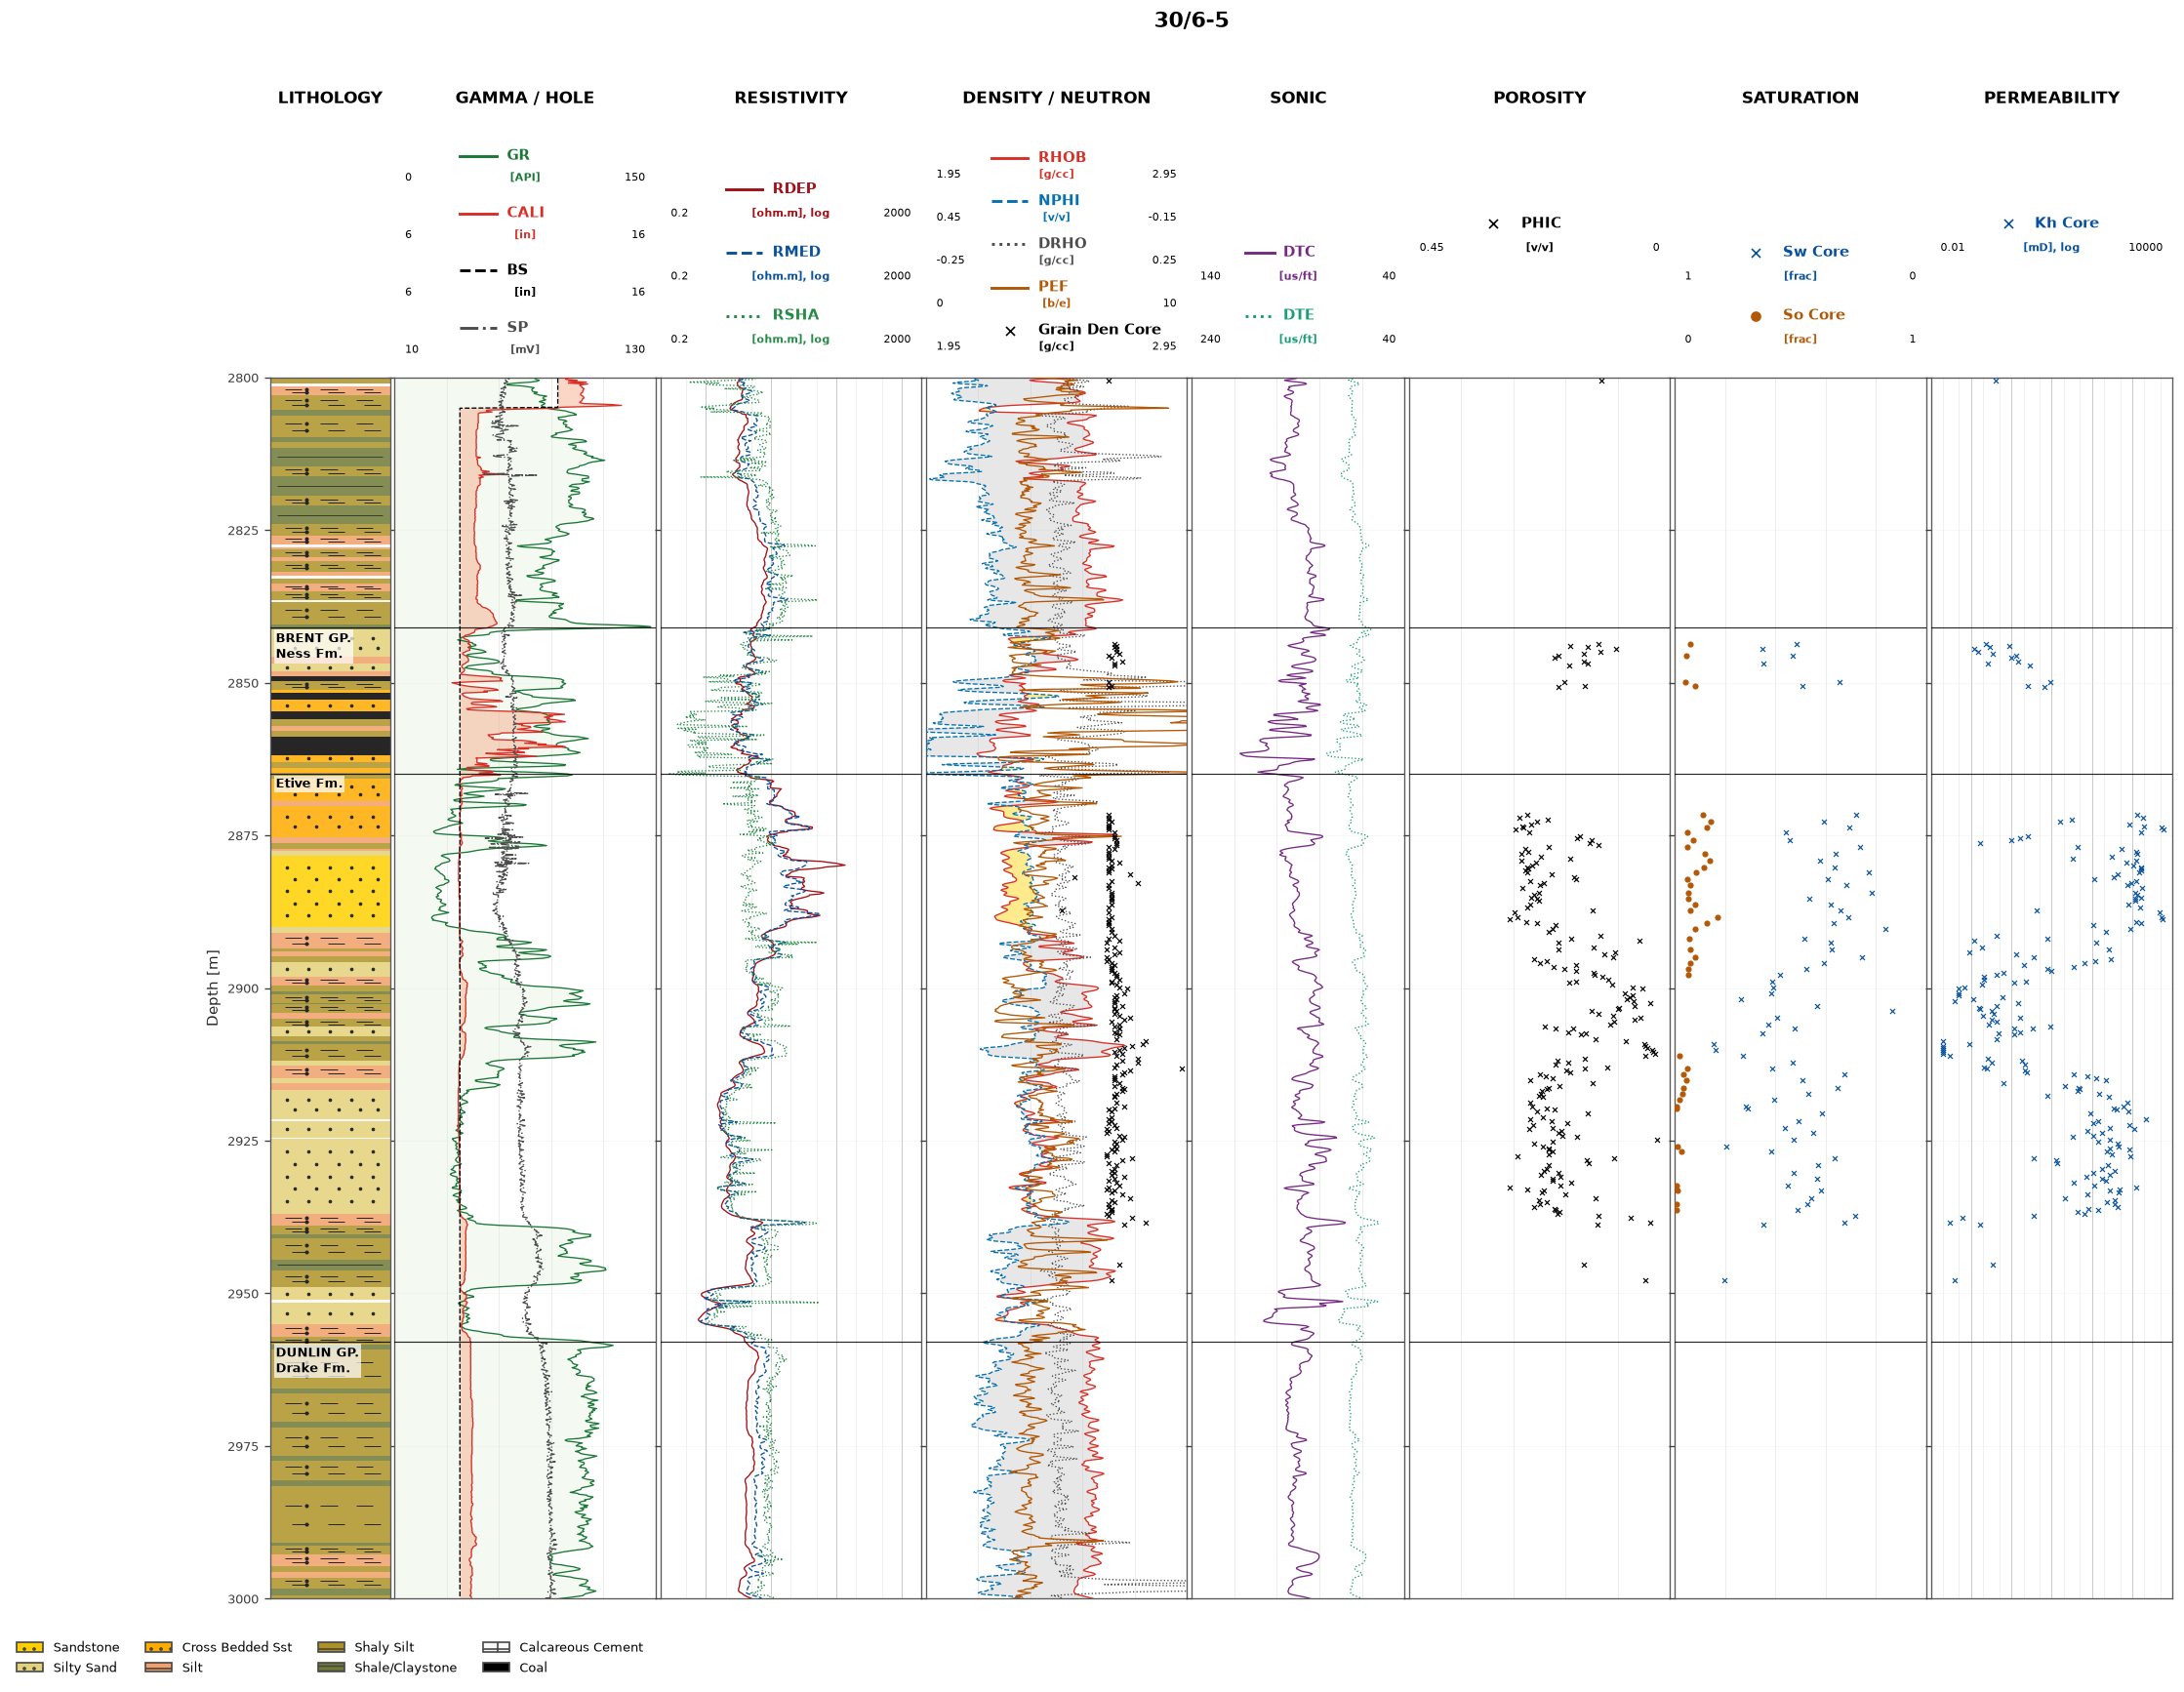

In [4]:
viewer = pp.plot(well, top=2800, bottom=3000, formations=TOPS)
viewer.warnings

### Data readiness check

The plot recorded some expected messages (`viewer.warnings`, above):

- The tops file records no depth reference or datum, so Petrophys assumes they match the well and
  says so.
- The core saturations `SWC` (water) and `SOC` (oil) are stored in percent although the LAS labels
  them `frac`. Petrophys divides them by 100 on a display copy, raises a `UserWarning` for each
  (printed above the figure) and records the same message in `viewer.warnings`, so you can
  verify the source file.

The same unit message comes back whenever a copy of this well is standardized, in `pp.interpret`
too. Since it is explained, the next cell hides exactly those two messages and nothing else.

In [5]:
warnings.filterwarnings("ignore", message="(SWC|SOC): inferred percent core saturation")

## Part 3 - The workflow plan

We use the library's **dynamic workflow**, called through `pp.interpret`, as the interpretation
backbone. It inspects the curves that are present and runs only the modules it can support, in
petrophysical order, recording a **step-by-step trace** we will use as the audit.

The core chain it executes for 30/6-5 (each step references the tutorial that teaches it):

| # | Step | What it does | Key inputs |
|---|------|--------------|-----------|
| 1 | Temperature | Builds a temperature profile from an assumed surface temperature and the header BHT | depth, BHT |
| 2 | Bad-hole | Flags washed-out / rugose hole from CALI vs BS | CALI, BS, DRHO |
| 3 | Vcl | Volume of clay: the lower of the GR and neutron-density estimates (SP reported) | GR, RHOB, NPHI, SP |
| 4 | Porosity | Density-neutron total porosity PHIT and effective PHIE | RHOB, NPHI |
| 5 | Lithology | Multi-mineral solve (quartz / calcite / dolomite / clay) | RHOB, NPHI, PEF |
| 6 | Core correction | Ties log porosity/perm to core; the porosity fit is made on PHIT and used only if it passes a quality gate | PHIC, KH_CORE |
| 7 | Rw | Formation-water resistivity, temperature-corrected along the profile | Rw + its temperature |
| 8 | Saturation | Water saturation Sw (Archie family, auto-routed) | RDEP, PHIE, Rw |
| 9 | Permeability | Log permeability, core-calibrated where possible | PHIE, core |
| 10 | Rock quality | RQI / FZI flow indicators | PHIE, PERM |
| 11 | Net pay | 3-stage cutoffs -> net rock / net reservoir / net pay; bad-hole, evaporite and coal samples left out | Vcl, PHIE, Sw, BAD_HOLE |

The table lists the core chain. The engine also runs housekeeping and extra steps - curve
normalization, input-context selection, Rmf and shale resistivity (Rcl), invasion, bulk-volume water
(BVW) and the moveable-hydrocarbon index (MHI). Part 4
lists the exact steps it ran.

We then roll the sample-by-sample answer up to a **per-formation** summary using the bundled
formation tops, and finally turn that into a completion recommendation.

**Model choices and why:**

- **`lithology_domain="clastic"`, `matrix_type="sandstone"`.** 30/6-5 is a siliciclastic Jurassic
  section; the reservoirs are the Brent Group and Statfjord sands.
- **Saturation model = auto.** We let the workflow route to the appropriate Archie-family model.
  Case study CS5 does a dedicated Sw-model sensitivity; here we take the workflow's routed answer.
- **Environment from the header.** The LAS header records a BHT and an Rw together with the
  temperature at which that Rw applies (`RWT`), so none of them has to be invented. The surface
  temperature is the only environmental input we assume. Rw is one of the biggest levers on Sw
  (CS5 ranks it).

### Parameters: from the header, cross-checked

The header's parameter block gives us BHT (126 degC), Rmf (0.08 ohm.m) and
**Rw = 0.070 ohm.m at RWT = 230 degF** (reservoir temperature, sourced from the NPD well data;
printed above). Lesson 09 back-calculates the Rw the operator's completion-report evaluation used
and arrives at the same value, and that evaluation agrees with the NPD fact page for this well
(oil logged from 2841 m down to 2899 m, OWC from pressure data at 2907 m).

We pass the Rw explicitly - `rw=0.07` **and** `rw_meas_temp_f=230` - so it is recorded in the run
settings. The temperature matters: without it, Petrophys takes the Rw as the value at the median
formation temperature, warns that it did, and applies no temperature correction from 230 degF,
which changes Sw strongly.

Two more settings are choices we make, and pass so that they are visible in the audit:

- the **surface temperature**, 50 degF (about 10 degC, the North Sea seabed) - an assumption; the
  BHT anchors the other end of the temperature profile;
- the **net-pay cutoffs**, `VCL < 0.40`, `PHIE > 0.08`, `Sw < 0.60` - the clastic standards, set
  for every sample. Left unset, each sample would take the standard of its lithology family, so
  the carbonate beds of the vendor lithology log would get the carbonate set.

## Part 4 - Execution: run the interpretation and read its audit trace

One call runs the whole chain. Every keyword is a validated `DynamicWorkflowConfig` setting, so a
typo raises an error instead of being ignored. `pp.interpret` works on a **copy**: `well` stays the
raw LAS, and the interpreted curves live on `result.well`.

The result records which steps executed, which were skipped and why, and a full per-step trace.
We treat that trace as the **interpretation audit** - it is what makes the recommendation
defensible. First, what the run wants us to check:

In [6]:
SETTINGS = dict(rw=0.07, rw_meas_temp_f=230,   # header Rw and the temperature it applies at
                surface_temp_f=50,              # assumed: about 10 degC at the seabed
                vcl_cutoff=0.40, phie_cutoff=0.08, sw_cutoff=0.60)   # clastic standards
result = pp.interpret(well, **SETTINGS)
result.warnings

['lithology: PEF set aside: in 94% of 331 clean porous samples the apparent matrix density is quartz-like (< 2.67 g/cm3) but the apparent matrix U calcite-like (> 10 b/cm3), the signature of barite-weighted mud; minerals solved without PEF',
 "Bad hole removed 33.21 m of net pay (BAD_HOLE at 12631 of 22176 samples). Check the flag against the caliper and DRHO; bad_hole={'drho': ..., 'cali': ...} sets its thresholds and skip_steps=['bad_hole'] keeps the pay."]

Two warnings, both worth reading:

- **PEF set aside.** In the clean porous rock the apparent matrix density is quartz-like but the
  apparent matrix U calcite-like - the signature of barite-weighted mud - so the mineral solve
  runs on density-neutron alone (Part 7).
- **Bad hole.** The caliper and DRHO flag 12,631 of the 22,176 samples (57%) of the samples as bad hole, and the
  workflow keeps them out of net reservoir and pay: 33.2 m of pay that the cutoffs alone would
  have booked. Almost all of it lies in the washed-out shallow section (exercise 4 shows where).

### The step-by-step audit

One row per executed step with its method. Read it top-to-bottom: it is the paper trail from raw
logs to net pay. `result.print_trace()` prints every parameter and decision (long - try it
yourself), and `result.to_json(path)` saves the complete trace for a reviewer.

In [7]:
result.to_dataframe()[["Step", "Status", "Method"]]

,Step,Status,Method
0,normalization,OK,curve_alias_and_unit_standardization
1,input_context,OK,validated_geology_selection
2,temperature,OK,linear_gradient_from_BHT
3,bad_hole,OK,caliper_drho_flags
4,vclay,OK,linear
5,rcl,OK,lithology_shale_median_rt
6,rmf,OK,las_metadata_assumed_reference_temperature
7,porosity,OK,component_based
8,lithology,OK,canonical_multi_mineral_solver
9,core_correction,OK,same_well_core_correction


Besides porosity, four steps set the pay flag directly: clay volume, Rw, saturation and net pay.
Their decisions deserve a closer read - how VCL was combined, which Rw was used, which saturation
model ran at how many depths, and how many samples passed each cutoff and which were left out.

In [8]:
{name: result.step(name).decisions for name in ["vclay", "rw", "saturation", "net_pay"]}

{'vclay': ['GR_min = 21.6 (auto, P5 of GR)',
  'GR_max = 115.3 (auto, P95 of GR)',
  'Gamma-ray clay input: GR',
  'GR method: linear',
  'SP method: enabled',
  'N-D method: enabled',
  'SP_clean = 43.2 (auto, P5 of SP)',
  'SP_shale = 111.6 (auto, P95 of SP)',
  'Applied GR endpoints: 20 to 115.313 API',
  'GR bound (nearly flat GR guard): the clean GR pick 21.6 API was lowered to 20',
  'Final VCL = min(GR, ND) at each depth, range: 0.000 - 1.000',
  'VCL_SP is reported but left out of the minimum: SP baselines picked over the whole log mostly measure SP baseline drift, so it only fills depths with no GR or N-D value. Set both sp_min and sp_max to include it; they apply to the whole log, so only for an SP without baseline drift',
  'N-D clean line (sandstone): RHOB 2.65 g/cm3 at NPHI -0.02 to RHOB 1.99 g/cm3 at NPHI 0.38',
  'N-D clay point: RHOB 2.346 g/cm3, NPHI 0.409, the median of 816 good-hole shale-lithology samples at 2461.85-3544.96 m',
  "VCL_ND undefined at 8499 samples wi

### QC decision: check where the flag fired

The workflow wrote `NET_PAY`, `PHIE`, `SW` and `PERM` onto `result.well`. Before we trust any
number we check *where* the net-pay flag fired: the depth distribution should be geologically
sensible, and for a discovery well we can hold it against the public record. The bundled tops
mix groups and the formations inside them; `rank="group"` summarizes the coarsest level, so
every depth is counted once. PHIE, Sw and VCL are averaged over the net-pay samples of each
group (blank where it has none), RDEP over the whole group.

In [9]:
groups = result.formation_summary(TOPS, rank="group")
groups[["Formation", "Top", "Bottom", "Net Pay (m)", "Avg PHIE", "Avg Sw", "Avg VCL", "Avg RDEP"]]

[repository]\src\petrophys\workflow\summary.py:237: UserWarning: PERM_CC is undefined at some net-pay samples (HORDALAND GP. 31 of 31; VIKING GP. 1 of 2); each average covers the other pay samples.
  return analyze_formations(well, zones).to_dataframe()


,Formation,Top,Bottom,Net Pay (m),Avg PHIE,Avg Sw,Avg VCL,Avg RDEP
0,NORDLAND GP.,181.0,726.0,0.000,NaN,NaN,NaN,5.409
1,HORDALAND GP.,879.0,1908.0,4.724,0.443,0.583,0.128,0.969
2,ROGALAND GP.,1908.0,2203.0,0.000,NaN,NaN,NaN,1.015
3,SHETLAND GP.,2203.0,2408.0,0.000,NaN,NaN,NaN,1.412
4,CROMER KNOLL GP.,2408.0,2452.0,0.000,NaN,NaN,NaN,1.613
5,VIKING GP.,2452.0,2841.0,0.305,0.296,0.567,0.057,4.039
6,BRENT GP.,2841.0,2958.0,24.384,0.213,0.290,0.054,8.341
7,DUNLIN GP.,2958.0,3223.0,0.000,NaN,NaN,NaN,5.356


Read the distribution before any total:

- **The Brent Group** (24.4 m of pay) is the reason the well was drilled. Part 6 holds it
  against the public record.
- **Flags anywhere else** - in the shallow overburden (the Hordaland Group, 4.7 m) or in the
  Viking Group mudstones directly above the Brent Group (0.3 m) - need a reason before they
  count. The well found no hydrocarbons in either.

A whole-well net-pay total therefore mixes a discovery with whatever else passes the cutoffs:

In [10]:
{"whole well": result.summary()["net_thickness"]["net_pay"],
 "Brent Group": result.summary(top=2841, bottom=2958)["net_thickness"]["net_pay"]}

{'whole well': 30.17, 'Brent Group': 24.38}

#### Why the overburden can pass the cutoffs - and why it is not pay

Compare the Hordaland and Brent rows of the group table:

- **Porosity.** The Nordland and Hordaland sediments are young and poorly consolidated, so
  density-neutron porosity reads far higher than in the Brent Group sands (0.44 against
  0.21 over the flagged samples), far above the 8 pu cutoff.
- **Clay volume.** The workflow takes VCL as the lower of the GR and neutron-density estimates
  (the `vclay` decisions above). In soft, water-rich mudstone the indicators disagree: the
  neutron reads beyond the neutron-density triangle, where the workflow leaves VCL_ND undefined,
  so VCL falls back to the gamma ray, which reads these young sediments as fairly clean.
- **Water saturation.** The Rw was reconciled for the Brent Group brine and is corrected only for
  temperature, so it is higher in the cool shallow section (the `rw` and `saturation` decisions
  give its range along the well). Shallow pore water need not have the reservoir's salinity, so
  Archie Sw there is not reliable; it only has to fall just under the 0.60 cutoff for the flag
  to fire (mean 0.58 over the flagged samples), and the deep resistivity is low (0.97 ohm.m on
  average over the Hordaland Group against 8.3 ohm.m over the Brent Group) - not a hydrocarbon
  signature.

None of this is pay: the NPD records no hydrocarbons in the overburden, and no engineer would
perforate it. The cure is not a special cutoff but **scope**: evaluate the reservoir formations, not
the whole hole. The same scoping protects the answer from the mudstones of the Viking Group (Draupne
and Heather formations), which seal the Brent Group. This is why a whole-well net-pay total is never
the deliverable.

> Petrophys's default interpretation settings can flag the shallow section in the same way. Whatever
> settings you use, choose the reservoir interval explicitly - with
> `result.summary(top=..., bottom=...)` or a formation summary - before quoting pay.

## Part 5 - Integrated result

### 5a. Deliverable (b): the per-formation roll-up

`rank="formation"` keeps only the formation picks, so no depth is counted twice. (Groups without
formation picks, such as the Nordland Group, therefore do not appear; the group view above
covered them.) Each row gives gross, net pay, pay / gross, averages over the pay and a
hydrocarbon-pore-thickness index (HCPV, metres of hydrocarbon-filled pore column - not a
volumetric OOIP); the full table has net rock, net reservoir and more averages besides.

In [11]:
formations = result.formation_summary(TOPS, rank="formation")
formations[["Formation", "Top", "Bottom", "Gross (m)", "Net Pay (m)", "Pay/Gross",
            "Avg PHIE", "Avg Sw", "Avg VCL", "Avg Perm (mD)", "HCPV"]]

[repository]\src\petrophys\workflow\summary.py:237: UserWarning: PERM_CC is undefined at some net-pay samples (Heather Fm. 1 of 2; Statfjord Fm. 3 of 5); each average covers the other pay samples.
  return analyze_formations(well, zones).to_dataframe()


,Formation,Top,Bottom,Gross (m),Net Pay (m),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD),HCPV
0,Utsira Fm.,726.0,879.0,153.010,0.000,0.000,NaN,NaN,NaN,NaN,NaN
1,Balder Fm.,1908.0,2023.0,115.062,0.000,0.000,NaN,NaN,NaN,NaN,NaN
2,Sele Fm.,2023.0,2123.0,99.974,0.000,0.000,NaN,NaN,NaN,NaN,NaN
3,Lista Fm.,2123.0,2203.0,80.010,0.000,0.000,NaN,NaN,NaN,NaN,NaN
4,Draupne Fm.,2452.0,2593.0,140.970,0.000,0.000,NaN,NaN,NaN,NaN,NaN
5,Heather Fm.,2593.0,2841.0,247.955,0.305,0.001,0.296,0.567,0.057,10000.000,0.039
6,Ness Fm.,2841.0,2865.0,24.079,1.829,0.076,0.210,0.528,0.027,200.544,0.182
7,Etive Fm.,2865.0,2958.0,92.964,22.555,0.243,0.213,0.270,0.056,337.956,3.569
8,Drake Fm.,2958.0,3071.0,113.081,0.000,0.000,NaN,NaN,NaN,NaN,NaN
9,Cook Fm.,3071.0,3123.0,51.968,0.000,0.000,NaN,NaN,NaN,NaN,NaN


### 5b. Deliverable (a): the multi-track interpretation plot

`pp.plot(result, template="petrophysics")` lays out the standard interpretation panel from the
curves the workflow wrote, here over the Brent Group window (2800-3000 m):

- **Depth** and **lithology** - the depth column plus the vendor lithology track.
- **GR / Vcl** - gamma ray with the computed clay volume.
- **Resistivity** - deep / medium / shallow curves on a log scale.
- **Neutron / density / sonic** - the raw porosity-tool triplet (NPHI, RHOB, DTC).
- **Porosity** - the porosity family, the core-corrected PHIE_CC and core porosity points (PHIC).
- **Saturation** - Sw with the flushed-zone Sxo, BVW and apparent Swirr, plus core saturation
  points (SWC).
- **Permeability** - PERM / PERM_CC on a log scale against core KH_CORE points.
- **Flags** - the net-rock / net-reservoir / net-pay cutoff flags, shaded.

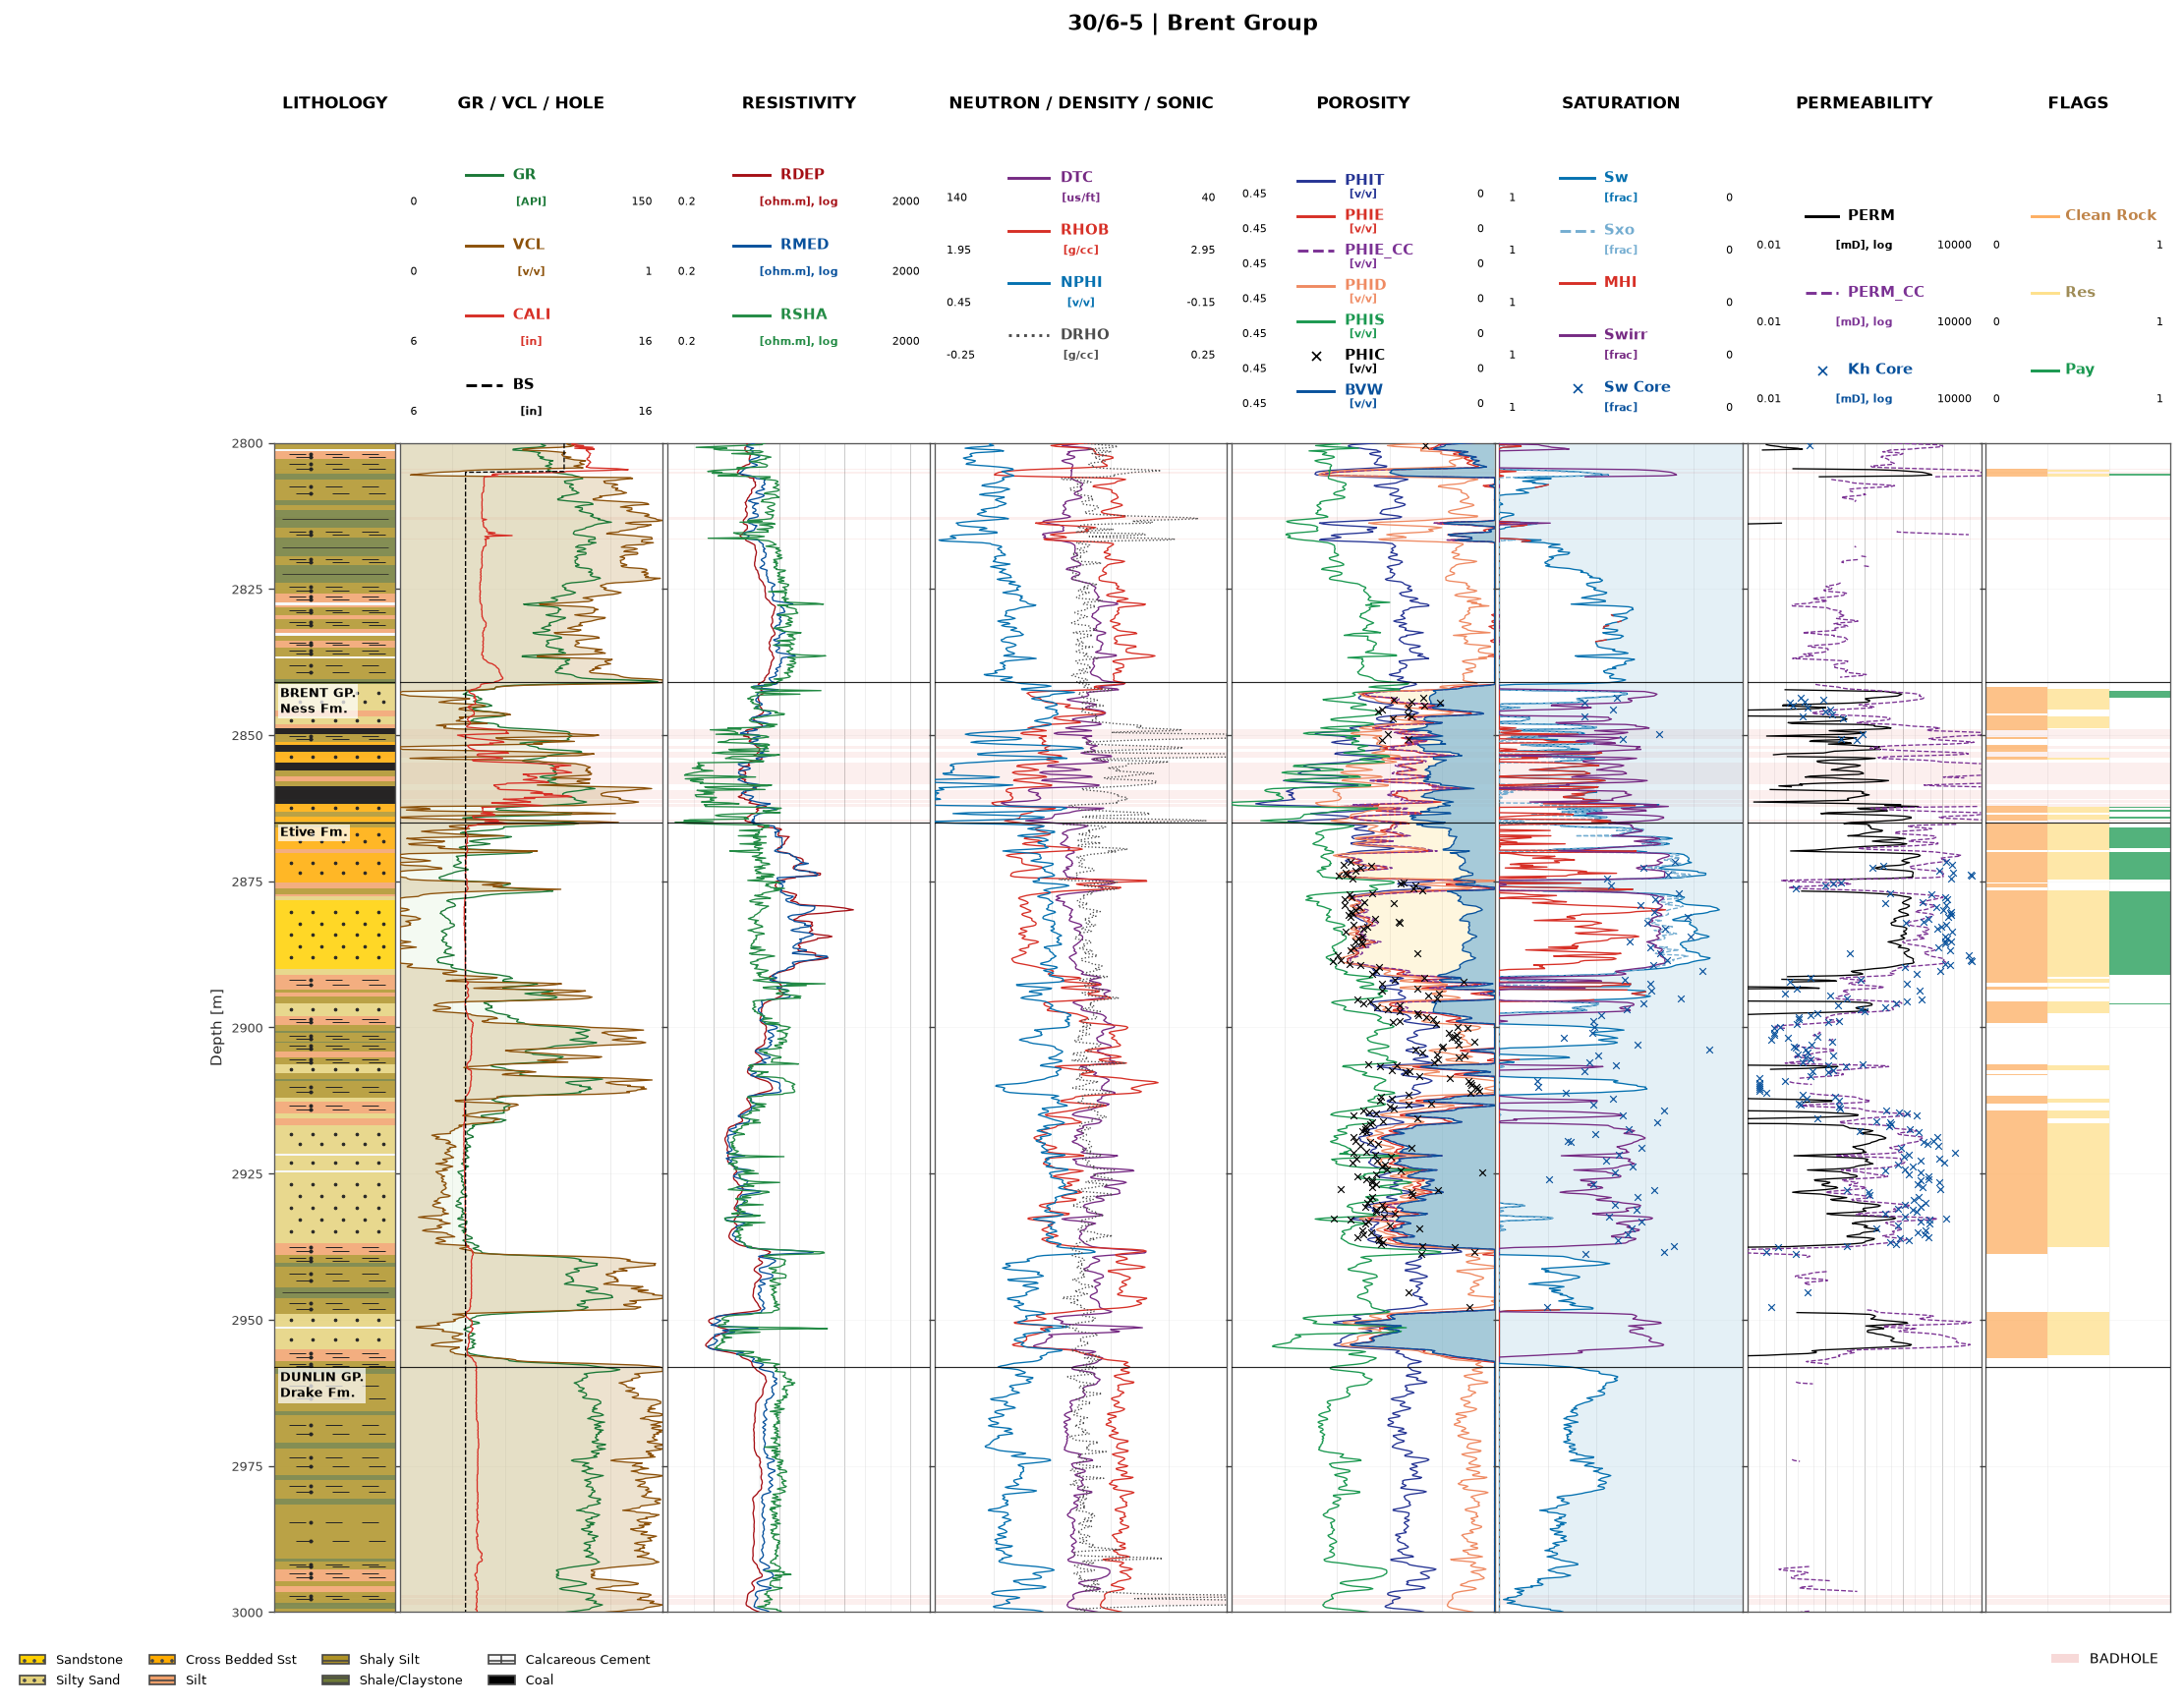

In [12]:
pp.plot(result, top=2800, bottom=3000, template="petrophysics", formations=TOPS,
        formation_name="Brent Group").show()

## Part 6 - Interpretation and the deliverable

### What the numbers mean

Reading the tables and the plot together, 30/6-5 has **one strong reservoir package** - which is
exactly what the well's history says:

- **Etive Fm. (Brent Group).** The clean, blocky sand: the lowest Sw of the reservoir formations
  (0.27) and by far the largest hydrocarbon pore thickness (3.57 m). This is the discovery.
- **Ness Fm. (Brent Group).** Real but poorer pay: 1.8 m with Sw 0.53, close to the cutoff. It sits
  directly on top of the Etive and is completed with it, not separately.
- **Statfjord Fm.** Only scattered flags (0.8 m in 333 m of gross, pay / gross 0.002),
  consistent with the NPD record, which reports no Statfjord discovery in this well. Not a target.
- **Cook Fm.** books no pay.
- **Everything else** - the overburden and the Viking Group mudstones - was set aside for the
  reasons given in Part 4.

The operator's 1981 evaluation (validated in lesson 09) reached the same conclusion with its own
zonation: pay in the Etive and Ness, and the sand below them (its "Drake sand", 2895-2939 m)
essentially wet. The NPD fact page reports oil from 2841 m down to 2899 m and an oil-water
contact (OWC) at 2907 m from pressure data. `zone_summary` takes any intervals, so the Brent
Group pay can be split at those depths:

In [13]:
NPD = [{"zone": "Logged oil (NPD)", "top": 2841, "bottom": 2899},
       {"zone": "Oil base to OWC", "top": 2899, "bottom": 2907},
       {"zone": "Below the OWC", "top": 2907, "bottom": 2958}]
result.zone_summary(NPD)[["Zone", "Top", "Bottom", "Net Pay (m)", "Avg Sw"]]

,Zone,Top,Bottom,Net Pay (m),Avg Sw
0,Logged oil (NPD),2841.0,2899.0,24.384,0.29
1,Oil base to OWC,2899.0,2907.0,0.000,NaN
2,Below the OWC,2907.0,2958.0,0.000,NaN


All of the Brent Group pay lies in the logged oil column; none of it reaches the OWC. The log
evaluation and the public record agree.

### Deliverable (c): ranked candidate completion intervals

The ranking comes straight from the per-formation roll-up: the Jurassic sandstones the well was
drilled for (the Brent Group's **Ness** and **Etive** formations, the **Cook** Fm. inside the Dunlin
Group and the **Statfjord** Fm. near TD), sorted by hydrocarbon pore thickness (the volume proxy).

In [14]:
RESERVOIR = ["Ness Fm.", "Etive Fm.", "Cook Fm.", "Statfjord Fm."]
ranked = formations[formations["Formation"].isin(RESERVOIR)].sort_values("HCPV", ascending=False)
ranked[["Formation", "Top", "Bottom", "Net Pay (m)", "Pay/Gross", "Avg PHIE", "Avg Sw",
        "Avg Perm (mD)", "HCPV"]]

,Formation,Top,Bottom,Net Pay (m),Pay/Gross,Avg PHIE,Avg Sw,Avg Perm (mD),HCPV
7,Etive Fm.,2865.0,2958.0,22.555,0.243,0.213,0.270,337.956,3.569
6,Ness Fm.,2841.0,2865.0,1.829,0.076,0.210,0.528,200.544,0.182
11,Statfjord Fm.,3223.0,3556.0,0.762,0.002,0.305,0.413,744.078,0.141
9,Cook Fm.,3071.0,3123.0,0.000,0.000,NaN,NaN,NaN,NaN


Two simple rules turn the table into a recommendation: a formation whose pay / gross is below 0.05
is **marginal** (scattered flags, not a completion target); otherwise the largest HCPV is the
**primary target**, and other formations of the same group are completed with it.

| Rank | Formation | Call | Why |
|---|---|---|---|
| 1 | Etive Fm. | **primary target** | largest HCPV (3.57 m), Sw 0.27, pay / gross 0.24 |
| 2 | Ness Fm. | **secondary - complete with the Etive** | same group, pay / gross 0.08, Sw 0.53 |
| 3 | Statfjord Fm. | marginal - do not perforate | pay / gross 0.002, scattered flags |
| 4 | Cook Fm. | no pay | - |

**Recommendation in one line:** complete the **Brent Group sands (Ness + Etive, 2841-2958 m)**,
where the flagged pay sits above the NPD's 2907 m OWC; the **Statfjord Fm.** carries only scattered,
marginal flags (the NPD records no Statfjord discovery here) and is not a completion candidate; the
overburden flags are not pay. One target, consistent with both the operator's 1981 evaluation and
the NPD fact page.

## Part 7 - Limitations and assumptions

An interpretation is only as trustworthy as its caveats. The material ones for 30/6-5:

- **Rw is taken from the header, not measured by us.** The LAS parameter block gives
  **0.070 ohm.m at 230 degF** (NPD well data), and lesson 09's back-calculation of the operator's
  evaluation reproduces it; we applied it with its temperature (`rw=0.07`,
  `rw_meas_temp_f=230`). Sw scales roughly with `sqrt(Rw)`, so this is one of the biggest levers
  on the answer; case study **CS5** ranks it against m, n and the clay cutoff.
- **The overburden is the failure mode to watch.** The unconsolidated Nordland/Hordaland
  sediments read very high porosity, the clay indicators disagree in their soft mudstones, and the
  Rw calibrated for the Brent Group brine - one Rw, corrected only for temperature, for the whole well,
  while shallow water is usually fresher - lets Sw fall just under the cutoff, so part of the
  shallow section is flagged (Part 4). Restricting the evaluation to named reservoir formations
  keeps it out of the answer; a zone Rw for the shallow section (`zones=`) would address the cause.
- **Bad hole is left out, not repaired.** The caliper/DRHO flag keeps washed-out samples out of
  net reservoir and pay - 33.2 m of pay over the whole well, almost all of it washed-out
  overburden that was never pay. Exercise 4 checks how little of it is in the Brent Group.
- **PEF only over a narrow window, and set aside in this run.** PEF is recorded only from 2784 m to
  3176 m, which ends above the Statfjord. Inside that window the lithology step set it aside (its
  warning in Part 4: the signature of barite-weighted mud), so the multi-mineral solve rests on
  density-neutron at every depth and the mineral volumes carry extra uncertainty.
- **Groups and formations overlap.** The bundled tops nest formations inside groups.
  `formation_summary(rank="formation")` (or `rank="group"`) picks one level so no depth is counted
  twice; never add rows from both levels.
- **One whole-well core calibration.** The tops were kept out of `pp.interpret`, so core porosity and
  permeability are calibrated with all core points at once rather than formation by formation. Ness
  has only a few core points of its own.
- **Cutoffs are conventions.** `Vcl < 0.40`, `PHIE > 0.08`, `Sw < 0.60` are reasonable clastic
  defaults but are choices; moving them moves the net-pay totals. They are set explicitly above so
  they can be challenged.
- **HCPV here is a thickness index**, not a volumetric OOIP. It ranks zones per unit area; a true
  volumetric estimate needs area and formation-volume factor
  (`petrophys.evaluation.summaries.calculate_ooip`).

## Part 8 - Appendix: hand off the results, and reproduce this on another well

The whole evaluation is one `pp.interpret` call plus one formation roll-up. The hand-off files a
reviewer needs are the interpreted LAS (settings recorded as `PP_*` header parameters), the full
JSON trace and the formation table; the cell writes them to a `cs1_handoff` folder.

In [15]:
result.to_las("cs1_handoff/30_6-5_interpreted.las")
result.to_json("cs1_handoff/30_6-5_trace.json")
formations.to_csv("cs1_handoff/30_6-5_formation_summary.csv", index=False)

#### Applying this workflow to another well

Start with `pp.read` and `pp.plot` on the LAS alone. Add optional formation/lithology tables only
when available, using the [input templates](../../docs/input_templates.md). Formation analysis
requires bounded intervals or a justified terminal depth.

Then use `pp.interpret` with well-specific fluid, temperature and rock assumptions - always state the
temperature at which Rw applies. Inspect the trace, source selection, warnings and skipped steps
before interpreting the computed curves, check where the pay flag fires, and quote pay only over the
reservoir interval. The case-study parameters are not universal defaults.

### Recap

- We ran a full, auditable formation evaluation of discovery well 30/6-5 with one `pp.interpret`
  call and used its **step trace** as the interpretation audit.
- We checked **where the pay flag fired** before trusting totals: the Brent Group block is the
  discovery; the overburden flags are artefacts of soft, high-porosity sediment and a
  brine-calibrated Rw, and are removed by scoping the evaluation to reservoir formations.
- `result.formation_summary(TOPS, rank="formation")` gave the per-formation table without
  double-counting nested groups, and fed the three deliverables: a per-formation table, a composite
  plot and a **ranked completion plan**.
- The verdict: perforate the **Brent Group (Ness + Etive) sands** - the only real target, with the
  pay above the NPD's OWC. The Statfjord carries only scattered, marginal flags.
- The environment came from the **LAS header parameter block**, including Rw 0.070 ohm.m at
  230 degF, which lesson 09 cross-checks against the operator's evaluation.

### Exercises

1. **Default settings.** Run `pp.interpret(well, rw=0.07, rw_meas_temp_f=230)` with no other
   settings and compare `formation_summary(TOPS, rank="group")` with the group table in Part 4.
   Which groups change most, and which step decisions explain it?
2. **Cutoff sensitivity.** Re-run with `sw_cutoff=0.5`. How do the Etive and Ness net pay respond,
   and how does the overburden respond? What does that tell you about using a tighter cutoff as a
   cure for the shallow flags?
3. **Formation-specific calibration.** Read the well with
   `pp.read(pp.sample("30_6-5"), formations=TOPS)` and interpret it with the same `SETTINGS`; the
   `input_context` and `core_correction` decisions list the per-group and per-formation core
   models. Then attach one level only with `formation_options={"rank": "formation"}` and
   interpret again. Compare the Ness row of the formation table across the three runs. Which
   calibration would you defend, given how few core points Ness has?
4. **Keep the bad hole.** Re-run with `skip_steps=["bad_hole"]`. Where does the extra pay appear,
   and would you book any of it?

### What's next

**CS2** moves to a carbonate: core-calibrated rock typing over the Kharaib-2 interval of a COSTA
well. **CS5** returns to 30/6-5 to quantify how the saturation model and its parameters move the
Brent Group answer.